Logistic Regression - Binary classifiation:
Write your own logistic regression model for a binary
classification problem and compare your results with those from the same
model using scikit-learn.

Dataset: You may create your own artificial dataset, or use some standard binary classification dataset.

In [170]:
import numpy as np
def sigmoid(z):
  return 1/(1+np.exp(-z))
def fit_logistic_regression (X,y,learning_rate,iterations):
  num_samples,num_features=X.shape


  weights=np.zeros(num_features)
  bias=0.0


  for iteration in range (iterations):
    linear_model=np.dot(X,weights)+bias
    y_predicted=sigmoid(linear_model)


    dw=np.dot(X.T,(y_predicted-y))
    db=np.sum(y_predicted-y)

    weights=weights-(learning_rate*dw)
    bias=bias-(learning_rate*db)
  return weights,bias

def predict_probabilities(X,weights,bias):
  linear_model=np.dot(X,weights)+bias
  return sigmoid(linear_model)

def predict_class(X,weights,bias,threshold=0.5):
  probabilities=predict_probabilities(X,weights,bias)
  return np.where(probabilities>=threshold,1,0)

In [171]:
from sklearn.metrics import accuracy_score
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


np.random.seed(42)
X_base = np.random.randn(380, 2)
y_base = np.where(X_base[:,0] + 2 * X_base[:,1] + 1 > 1, 1, 0)
num_outliers = 20
X_outliers = np.random.uniform(low=-8, high=8, size=(num_outliers, 2))
y_outliers = np.random.randint(0, 2, size=num_outliers)
X_with_outliers = np.vstack((X_base, X_outliers))
y_with_outliers = np.hstack((y_base, y_outliers))

print(f"Shape of X with outliers: {X_with_outliers.shape}")
print(f"Shape of y with outliers: {y_with_outliers.shape}")
X_train, X_test, y_train, y_test = train_test_split(X_with_outliers, y_with_outliers, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


final_weights,final_bias=fit_logistic_regression(X_train_scaled,y_train,learning_rate=0.01,iterations=4000)
y_pred_scratch=predict_class(X_test_scaled,final_weights,final_bias)


Shape of X with outliers: (400, 2)
Shape of y with outliers: (400,)


In [172]:
from sklearn.linear_model import LogisticRegression

model=LogisticRegression()
model.fit(X_train_scaled,y_train)

y_pred=model.predict(X_test_scaled)


In [173]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)
print('Confusion Matrix (sklearn implementation):')
print(cm)


Confusion Matrix (sklearn implementation):
[[35  4]
 [ 2 39]]


In [174]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
print("Scratch Model")
print("Accuracy :", accuracy_score(y_test, y_pred_scratch))
print("Precision:", precision_score(y_test, y_pred_scratch))
print("Recall   :", recall_score(y_test, y_pred_scratch))
print("F1 Score :", f1_score(y_test, y_pred_scratch))

print("\nScikit-learn Model")
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))


Scratch Model
Accuracy : 0.925
Precision: 0.9069767441860465
Recall   : 0.9512195121951219
F1 Score : 0.9285714285714286

Scikit-learn Model
Accuracy : 0.925
Precision: 0.9069767441860465
Recall   : 0.9512195121951219
F1 Score : 0.9285714285714286


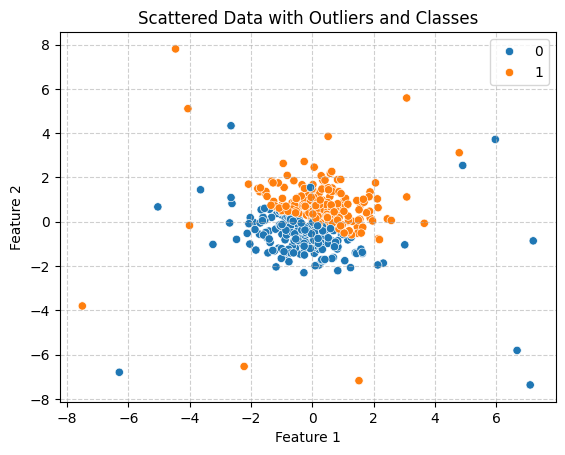

In [175]:
import matplotlib.pyplot as plt

sns.scatterplot(x=X_with_outliers[:,0],y=X_with_outliers[:,1],hue=y_with_outliers)
plt.title('Scattered Data with Outliers and Classes')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()